<a href="https://colab.research.google.com/github/skarahajimaruore/master-research/blob/main/Research_sample_analysis_hyperthesis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
import pandas as pd

df = pd.read_csv("/content/sns_simulation_500_long.csv")

youtube_df = df[df["SNS"] == "YouTube"].copy()

In [12]:
youtube_df[
    [
        "weekday_free_min",
        "daily_minutes",
        "sns_to_free_ratio",
        "satisfaction_1_7",
        "regret_1_7"
    ]

].describe()

,weekday_free_min,daily_minutes,sns_to_free_ratio,satisfaction_1_7,regret_1_7
count,408.000000,408.000000,408.000000,408.000000,408.000000
mean,247.267157,62.573529,0.302620,4.894608,3.571078
std,104.411630,43.082909,0.235773,0.979480,1.451881
min,60.000000,5.000000,0.011905,3.000000,1.000000
25%,170.000000,30.000000,0.127660,4.000000,3.000000
50%,237.500000,55.000000,0.240000,5.000000,3.000000
75%,315.000000,85.000000,0.417763,6.000000,4.000000
max,570.000000,320.000000,1.384615,7.000000,7.000000


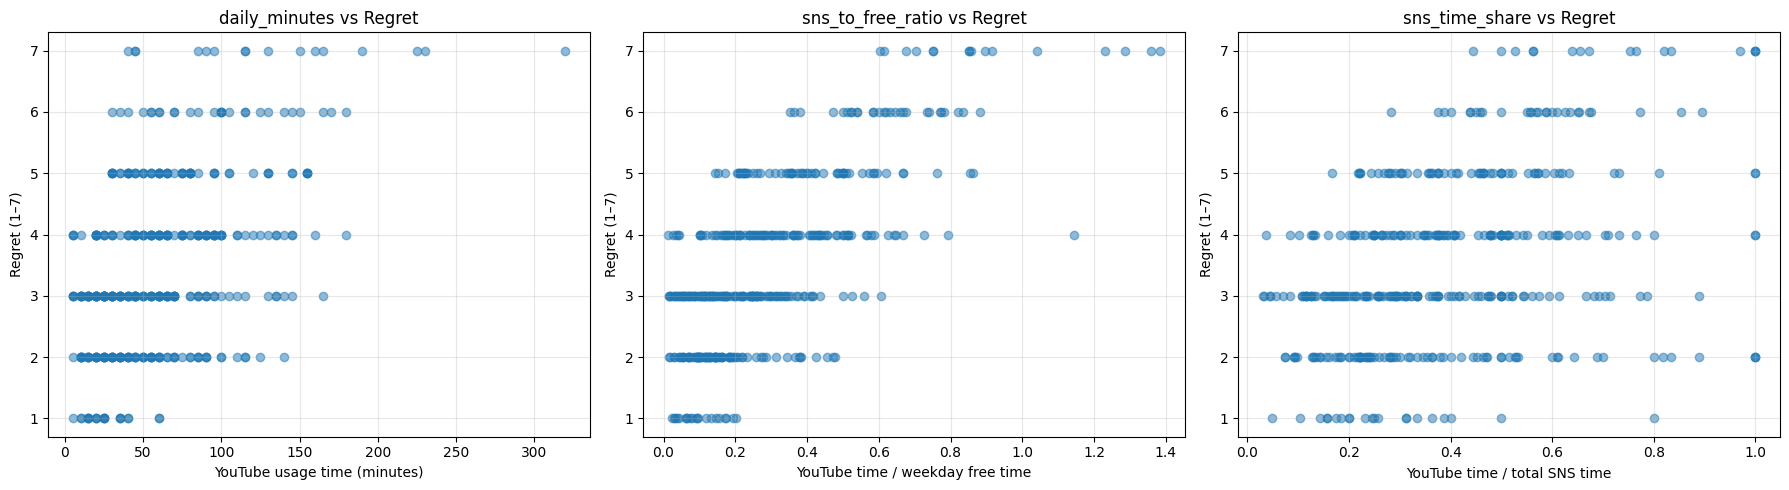

In [8]:
import matplotlib.pyplot as plt

variables = [
    ("daily_minutes", "YouTube usage time (minutes)"),
    ("sns_to_free_ratio", "YouTube time / weekday free time"),
    ("sns_time_share", "YouTube time / total SNS time")
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (col, label) in zip(axes, variables):
    ax.scatter(
        youtube_df[col],
        youtube_df["regret_1_7"],
        alpha=0.5
    )

    ax.set_xlabel(label)
    ax.set_ylabel("Regret (1–7)")
    ax.set_title(f"{col} vs Regret")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [6]:
youtube_df[
    [
        "daily_minutes",
        "sns_to_free_ratio",
        "satisfaction_1_7",
        "regret_1_7"
    ]
].corr()

,daily_minutes,sns_to_free_ratio,satisfaction_1_7,regret_1_7
daily_minutes,1.000000,0.725555,-0.198216,0.487477
sns_to_free_ratio,0.725555,1.000000,-0.244279,0.718011
satisfaction_1_7,-0.198216,-0.244279,1.000000,-0.297938
regret_1_7,0.487477,0.718011,-0.297938,1.000000


In [9]:
import statsmodels.api as sm

X = youtube_df[["daily_minutes"]]
X = sm.add_constant(X)

y = youtube_df["regret_1_7"]

model = sm.OLS(y, X).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             regret_1_7   R-squared:                       0.238
Model:                            OLS   Adj. R-squared:                  0.236
Method:                 Least Squares   F-statistic:                     126.6
Date:                Sat, 17 Oct 2026   Prob (F-statistic):           9.67e-26
Time:                        02:18:42   Log-Likelihood:                -675.20
No. Observations:                 408   AIC:                             1354.
Df Residuals:                     406   BIC:                             1362.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const             2.5431      0.111     22.932

In [ ]:
X = youtube_df[["sns_to_free_ratio"]]
X = sm.add_constant(X)

y = youtube_df["regret_1_7"]

model = sm.OLS(y, X).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             regret_1_7   R-squared:                       0.516
Model:                            OLS   Adj. R-squared:                  0.514
Method:                 Least Squares   F-statistic:                     432.0
Date:                Sun, 13 Sep 2026   Prob (F-statistic):           7.04e-66
Time:                        06:31:26   Log-Likelihood:                -582.71
No. Observations:                 408   AIC:                             1169.
Df Residuals:                     406   BIC:                             1177.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                 2.2330      0.08

In [ ]:
X = youtube_df[
    [
        "daily_minutes",
        "sns_to_free_ratio"
    ]
]

X = sm.add_constant(X)

y = youtube_df["regret_1_7"]

model = sm.OLS(y, X).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             regret_1_7   R-squared:                       0.518
Model:                            OLS   Adj. R-squared:                  0.516
Method:                 Least Squares   F-statistic:                     217.5
Date:                Sun, 13 Sep 2026   Prob (F-statistic):           6.82e-65
Time:                        06:34:33   Log-Likelihood:                -581.71
No. Observations:                 408   AIC:                             1169.
Df Residuals:                     405   BIC:                             1181.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                 2.2865      0.09

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
from lightgbm import LGBMRegressor

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
from lightgbm import LGBMRegressor

# 目的変数
y = youtube_df["regret_1_7"]

# -------------------------
# Model 1
# 絶対利用時間のみ
# -------------------------
X1 = youtube_df[
    [
        "daily_minutes"
    ]
]

X1_train, X1_test, y_train, y_test = train_test_split(
    X1,
    y,
    test_size=0.2,
    random_state=42
)

model1 = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.05,
    random_state=42,
    verbosity=-1
)

model1.fit(X1_train, y_train)

y_pred1 = model1.predict(X1_test)

mae1 = mean_absolute_error(
    y_test,
    y_pred1
)


# -------------------------
# Model 2
# 絶対時間 + 相対時間・配分
# -------------------------
X2 = youtube_df[
    [
        "daily_minutes",
        "sns_to_free_ratio",
        "total_sns_to_free_ratio",
        "sns_time_share"
    ]
]

X2_train, X2_test, y_train2, y_test2 = train_test_split(
    X2,
    y,
    test_size=0.2,
    random_state=42
)

model2 = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.05,
    random_state=42,
    verbosity=-1
)

model2.fit(X2_train, y_train2)

y_pred2 = model2.predict(X2_test)

mae2 = mean_absolute_error(
    y_test2,
    y_pred2
)


# -------------------------
# 結果比較
# -------------------------
print("Model 1 MAE:", mae1)
print("Model 2 MAE:", mae2)
print("MAE improvement:", mae1 - mae2)

Model 1 MAE: 1.0160061072213071
Model 2 MAE: 0.9129833625808784
MAE improvement: 0.10302274464042871


In [17]:
# =========================
# Regret Prediction
# LightGBM + 5-fold Cross Validation
# =========================

import numpy as np
import pandas as pd

from sklearn.model_selection import KFold, cross_val_score
from lightgbm import LGBMRegressor


# =========================
# 1. 目的変数
# =========================

y = youtube_df["regret_1_7"]


# =========================
# 2. 説明変数
# =========================

# Model 1：絶対利用時間のみ
features_1 = [
    "daily_minutes"
]

# Model 2：自由時間内利用割合・SNS間利用時間配分を追加
features_2 = features_1 + [
    "sns_to_free_ratio",
    "sns_time_share"
]

# Model 3：利用目的を追加
features_3 = features_2 + [
    "purpose_boredom",
    "purpose_entertainment",
    "purpose_news",
    "purpose_hobby",
    "purpose_study_work",
    "purpose_communication",
    "purpose_posting"
]

# Model 4：Big Fiveを追加
features_4 = features_3 + [
    "extraversion_score",
    "agreeableness_score",
    "conscientiousness_score",
    "neuroticism_score",
    "openness_score"
]


# =========================
# 3. Cross Validation
# =========================

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# =========================
# 4. モデル評価関数
# =========================

def evaluate_model(features, y):

    X = youtube_df[features]

    model = LGBMRegressor(
        n_estimators=300,
        learning_rate=0.05,
        random_state=42,
        verbosity=-1
    )

    mae_scores = -cross_val_score(
        model,
        X,
        y,
        cv=kf,
        scoring="neg_mean_absolute_error"
    )

    return mae_scores


# =========================
# 5. Model 1〜4を評価
# =========================

mae_scores1 = evaluate_model(features_1, y)
mae_scores2 = evaluate_model(features_2, y)
mae_scores3 = evaluate_model(features_3, y)
mae_scores4 = evaluate_model(features_4, y)


# =========================
# 6. 結果表示
# =========================

results = pd.DataFrame({
    "Model": [
        "Model 1",
        "Model 2",
        "Model 3",
        "Model 4"
    ],
    "Features": [
        "Absolute time",
        "+ Free time ratio & SNS time share",
        "+ Usage purposes",
        "+ Big Five"
    ],
    "N_features": [
        len(features_1),
        len(features_2),
        len(features_3),
        len(features_4)
    ],
    "Mean MAE": [
        mae_scores1.mean(),
        mae_scores2.mean(),
        mae_scores3.mean(),
        mae_scores4.mean()
    ],
    "SD": [
        mae_scores1.std(),
        mae_scores2.std(),
        mae_scores3.std(),
        mae_scores4.std()
    ]
})

results["MAE Improvement"] = (
    results["Mean MAE"].shift(1) - results["Mean MAE"]
)

display(results.round(4))


# =========================
# 7. 各FoldのMAE
# =========================

for i, scores in enumerate(
    [mae_scores1, mae_scores2, mae_scores3, mae_scores4],
    start=1
):
    print(f"Model {i} Fold MAE: {scores}")
    print(f"Model {i} Mean MAE: {scores.mean():.4f}")
    print()

,Model,Features,N_features,Mean MAE,SD,MAE Improvement
0,Model 1,Absolute time,1,1.0825,0.0345,NaN
1,Model 2,+ Free time ratio & SNS time share,3,0.9101,0.0175,0.1724
2,Model 3,+ Usage purposes,10,0.7895,0.0297,0.1207
3,Model 4,+ Big Five,15,0.7841,0.0249,0.0054


Model 1 Fold MAE: [1.01600611 1.10377389 1.0830744  1.0994964  1.11035209]
Model 1 Mean MAE: 1.0825

Model 2 Fold MAE: [0.92877104 0.92904501 0.88483249 0.89671703 0.91136935]
Model 2 Mean MAE: 0.9101

Model 3 Fold MAE: [0.82722698 0.81217855 0.75988026 0.750444   0.7975427 ]
Model 3 Mean MAE: 0.7895

Model 4 Fold MAE: [0.80714657 0.76254816 0.76177119 0.7680582  0.82076063]
Model 4 Mean MAE: 0.7841



In [ ]:
# -------------------------
# Model 3
# Model 2 + 利用目的
# -------------------------

X3 = youtube_df[
    [
        "daily_minutes",
        "sns_to_free_ratio",
        "total_sns_to_free_ratio",
        "sns_time_share",
        "purpose_boredom",
        "purpose_entertainment",
        "purpose_news",
        "purpose_hobby",
        "purpose_study_work",
        "purpose_communication",
        "purpose_posting"
    ]
]

model3 = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.05,
    random_state=42,
    verbosity=-1
)

mae_scores3 = -cross_val_score(
    model3,
    X3,
    y,
    cv=kf,
    scoring="neg_mean_absolute_error"
)

print("Model 1 Mean MAE:", mae_scores1.mean())
print("Model 2 Mean MAE:", mae_scores2.mean())
print("Model 3 Mean MAE:", mae_scores3.mean())

Model 1 Mean MAE: 1.0825405766733278
Model 2 Mean MAE: 0.8967551240591115
Model 3 Mean MAE: 0.7850451684357918


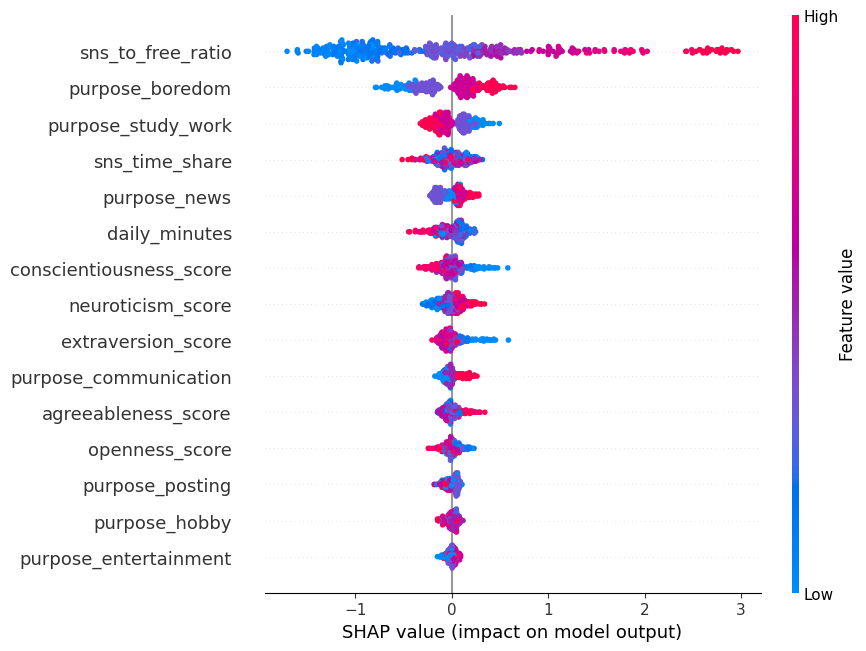

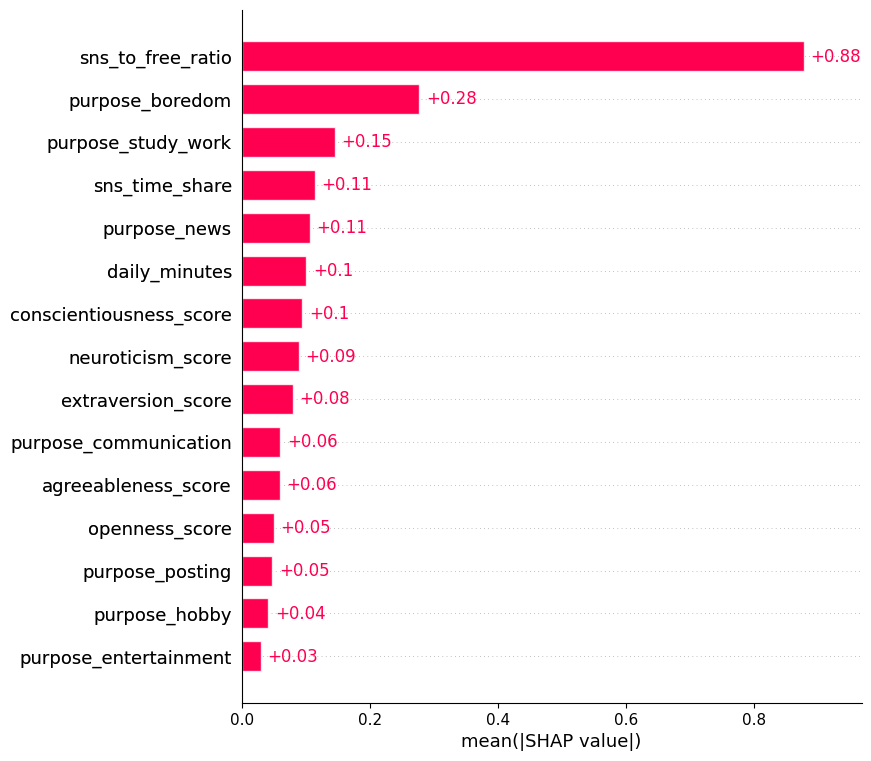

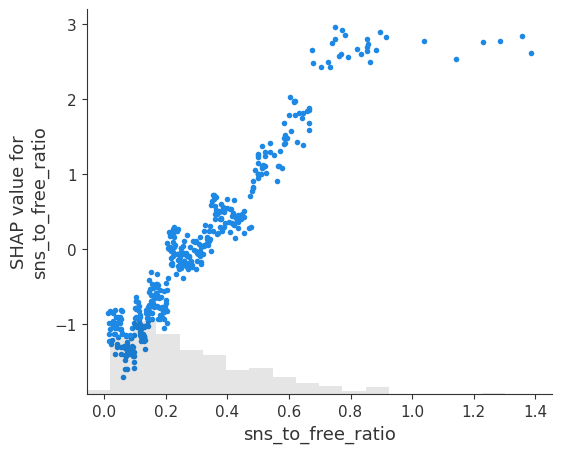

In [18]:
import shap
import matplotlib.pyplot as plt
from lightgbm import LGBMRegressor

# =========================
# 1. Model 4を全データで学習
# =========================

X4 = youtube_df[features_4]
y = youtube_df["regret_1_7"]

model4 = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.05,
    random_state=42,
    verbosity=-1
)

model4.fit(X4, y)

# =========================
# 2. SHAP値の計算
# =========================

explainer = shap.TreeExplainer(model4)
shap_values = explainer(X4)

# =========================
# 3. Beeswarm Plot
# =========================

shap.plots.beeswarm(
    shap_values,
    max_display=15
)

# =========================
# 4. Bar Plot
# =========================

shap.plots.bar(
    shap_values,
    max_display=15
)

# =========================
# 5. Dependence Plot
# 自由時間内利用割合
# =========================

shap.plots.scatter(
    shap_values[:, "sns_to_free_ratio"]
)

plt.show()

In [15]:
# -------------------------
# Model 4
# Model 3 + Big Five
# -------------------------

X4 = youtube_df[
    [
        "daily_minutes",
        "sns_to_free_ratio",
        "total_sns_to_free_ratio",
        "sns_time_share",

        "purpose_boredom",
        "purpose_entertainment",
        "purpose_news",
        "purpose_hobby",
        "purpose_study_work",
        "purpose_communication",
        "purpose_posting",

        "extraversion_score",
        "agreeableness_score",
        "conscientiousness_score",
        "neuroticism_score",
        "openness_score"
    ]
]

model4 = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.05,
    random_state=42,
    verbosity=-1
)

mae_scores4 = -cross_val_score(
    model4,
    X4,
    y,
    cv=kf,
    scoring="neg_mean_absolute_error"
)

print("Model 1 Mean MAE:", mae_scores1.mean())
print("Model 2 Mean MAE:", mae_scores2.mean())
print("Model 3 Mean MAE:", mae_scores3.mean())
print("Model 4 Fold MAE:", mae_scores4)
print("Model 4 Mean MAE:", mae_scores4.mean())

print()
print(
    "Model 3 → Model 4 improvement:",
    mae_scores3.mean() - mae_scores4.mean()
)

NameError: name 'cross_val_score' is not defined

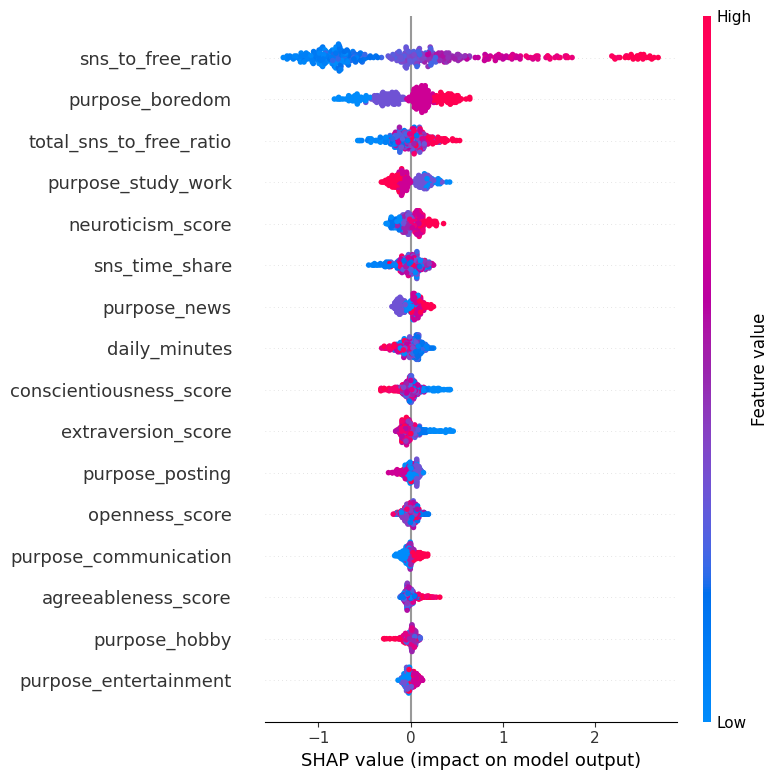

In [ ]:
model4.fit(X4, y)

explainer4 = shap.TreeExplainer(model4)

shap_values4 = explainer4.shap_values(X4)

shap.summary_plot(
    shap_values4,
    X4
)

ここまでは利用後悔

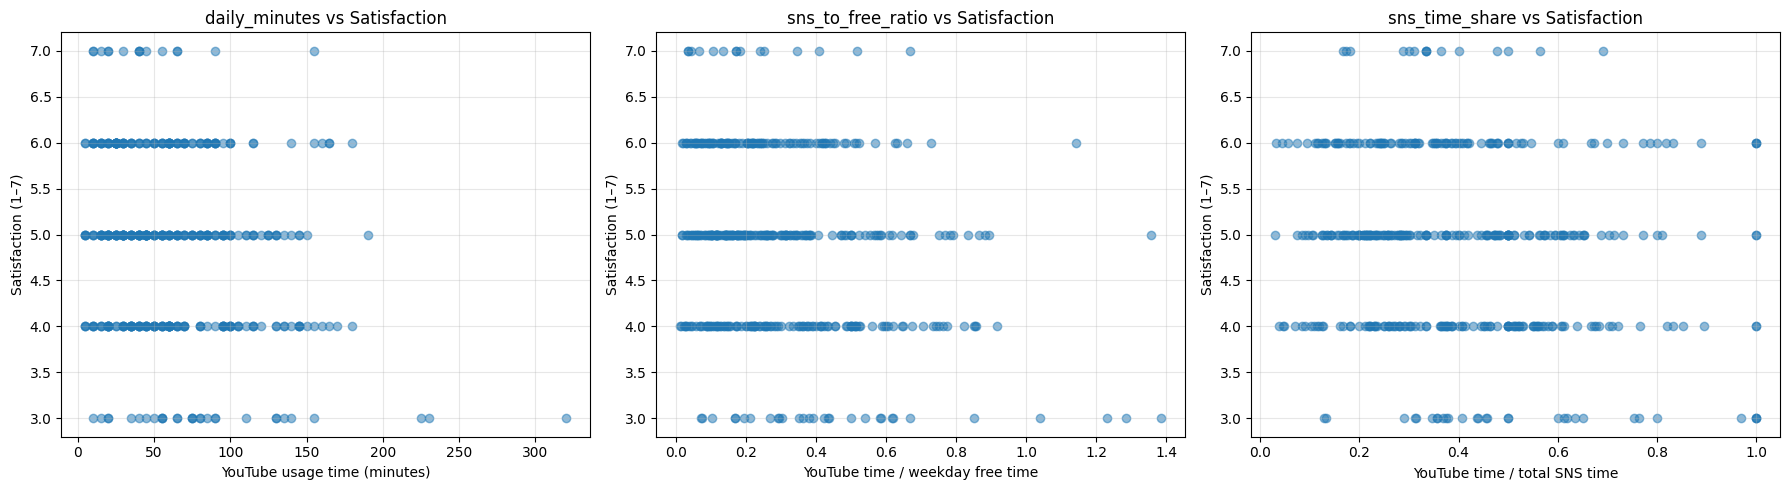

In [10]:
import matplotlib.pyplot as plt

variables = [
    ("daily_minutes", "YouTube usage time (minutes)"),
    ("sns_to_free_ratio", "YouTube time / weekday free time"),
    ("sns_time_share", "YouTube time / total SNS time")
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (col, label) in zip(axes, variables):
    ax.scatter(
        youtube_df[col],
        youtube_df["satisfaction_1_7"],
        alpha=0.5
    )

    ax.set_xlabel(label)
    ax.set_ylabel("Satisfaction (1–7)")
    ax.set_title(f"{col} vs Satisfaction")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [19]:
# =========================
# Satisfaction Prediction
# LightGBM + 5-fold Cross Validation
# =========================

import numpy as np
import pandas as pd

from sklearn.model_selection import KFold, cross_val_score
from lightgbm import LGBMRegressor


# =========================
# 1. 目的変数
# =========================

y_sat = youtube_df["satisfaction_1_7"]


# =========================
# 2. 説明変数
# =========================

# Model 1：絶対利用時間のみ
features_1_sat = [
    "daily_minutes"
]

# Model 2：自由時間内利用割合・SNS間利用時間配分を追加
features_2_sat = features_1_sat + [
    "sns_to_free_ratio",
    "sns_time_share"
]

# Model 3：利用目的を追加
features_3_sat = features_2_sat + [
    "purpose_boredom",
    "purpose_entertainment",
    "purpose_news",
    "purpose_hobby",
    "purpose_study_work",
    "purpose_communication",
    "purpose_posting"
]

# Model 4：Big Fiveを追加
features_4_sat = features_3_sat + [
    "extraversion_score",
    "agreeableness_score",
    "conscientiousness_score",
    "neuroticism_score",
    "openness_score"
]


# =========================
# 3. Cross Validation
# =========================

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# =========================
# 4. モデル評価関数
# =========================

def evaluate_model_sat(features, y):

    X = youtube_df[features]

    model = LGBMRegressor(
        n_estimators=300,
        learning_rate=0.05,
        random_state=42,
        verbosity=-1
    )

    mae_scores = -cross_val_score(
        model,
        X,
        y,
        cv=kf,
        scoring="neg_mean_absolute_error"
    )

    return mae_scores


# =========================
# 5. Model 1〜4を評価
# =========================

mae_sat_1 = evaluate_model_sat(features_1_sat, y_sat)
mae_sat_2 = evaluate_model_sat(features_2_sat, y_sat)
mae_sat_3 = evaluate_model_sat(features_3_sat, y_sat)
mae_sat_4 = evaluate_model_sat(features_4_sat, y_sat)


# =========================
# 6. 結果表示
# =========================

results_sat = pd.DataFrame({
    "Model": [
        "Model 1",
        "Model 2",
        "Model 3",
        "Model 4"
    ],
    "Features": [
        "Absolute time",
        "+ Free time ratio & SNS time share",
        "+ Usage purposes",
        "+ Big Five"
    ],
    "N_features": [
        len(features_1_sat),
        len(features_2_sat),
        len(features_3_sat),
        len(features_4_sat)
    ],
    "Mean MAE": [
        mae_sat_1.mean(),
        mae_sat_2.mean(),
        mae_sat_3.mean(),
        mae_sat_4.mean()
    ],
    "SD": [
        mae_sat_1.std(),
        mae_sat_2.std(),
        mae_sat_3.std(),
        mae_sat_4.std()
    ]
})

results_sat["MAE Improvement"] = (
    results_sat["Mean MAE"].shift(1)
    - results_sat["Mean MAE"]
)

display(results_sat.round(4))


# =========================
# 7. 各FoldのMAE
# =========================

for i, scores in enumerate(
    [mae_sat_1, mae_sat_2, mae_sat_3, mae_sat_4],
    start=1
):
    print(f"Model {i} Fold MAE: {scores}")
    print(f"Model {i} Mean MAE: {scores.mean():.4f}")
    print()

,Model,Features,N_features,Mean MAE,SD,MAE Improvement
0,Model 1,Absolute time,1,0.8216,0.1125,NaN
1,Model 2,+ Free time ratio & SNS time share,3,0.8831,0.0711,-0.0615
2,Model 3,+ Usage purposes,10,0.7696,0.0762,0.1135
3,Model 4,+ Big Five,15,0.7574,0.0960,0.0122


Model 1 Fold MAE: [0.98188219 0.74880191 0.65588404 0.83135981 0.89015122]
Model 1 Mean MAE: 0.8216

Model 2 Fold MAE: [0.95034064 0.78884126 0.81865236 0.88683228 0.97104229]
Model 2 Mean MAE: 0.8831

Model 3 Fold MAE: [0.81921826 0.64057383 0.72598169 0.81608229 0.84631757]
Model 3 Mean MAE: 0.7696

Model 4 Fold MAE: [0.78225031 0.62278653 0.66979166 0.84740012 0.86498097]
Model 4 Mean MAE: 0.7574



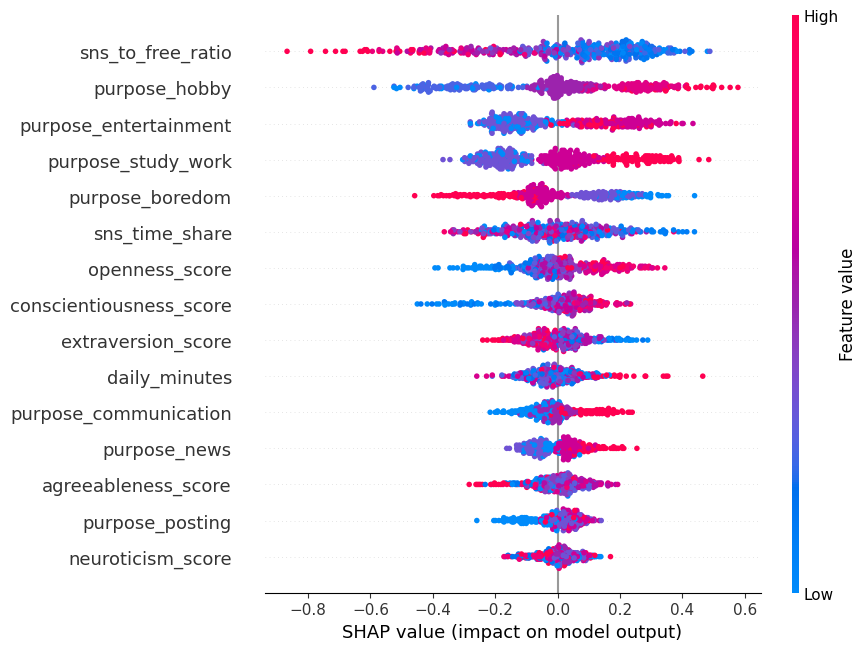

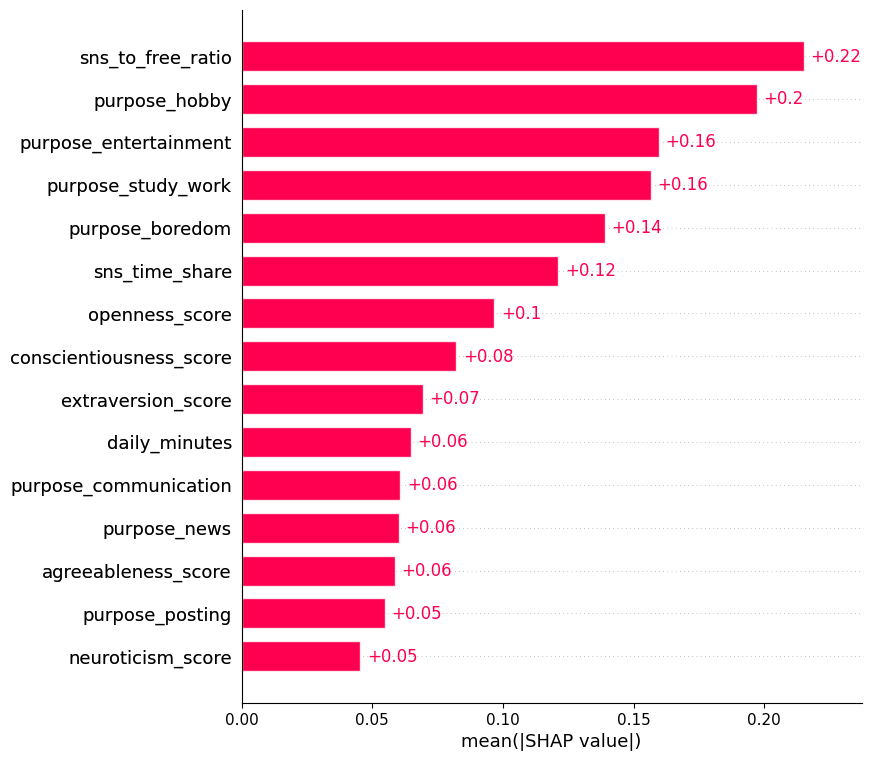

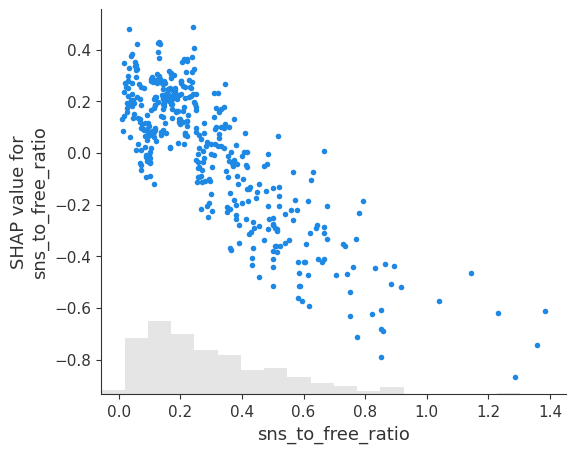

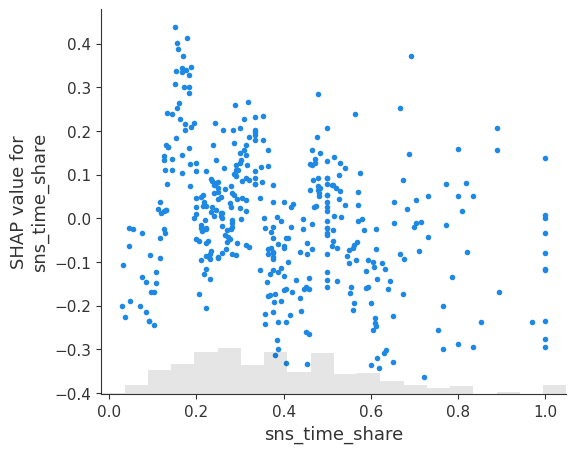

In [21]:
# =========================
# Satisfaction SHAP Analysis
# Model 4（15 features）
# =========================

import shap
import matplotlib.pyplot as plt
from lightgbm import LGBMRegressor

# 1. 説明変数・目的変数
X4_sat = youtube_df[features_4_sat]
y_sat = youtube_df["satisfaction_1_7"]

# 2. Model 4を全データで学習
model4_sat = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.05,
    random_state=42,
    verbosity=-1
)

model4_sat.fit(X4_sat, y_sat)

# 3. SHAP値の計算
explainer_sat = shap.TreeExplainer(model4_sat)
shap_values_sat = explainer_sat(X4_sat)

# 4. Beeswarm Plot
# 特徴量の重要度と予測への寄与方向
shap.plots.beeswarm(
    shap_values_sat,
    max_display=15
)
plt.show()

# 5. Bar Plot
# 特徴量の重要度ランキング
shap.plots.bar(
    shap_values_sat,
    max_display=15
)
plt.show()

# 6. Dependence Plot
# 自由時間内利用割合と満足度予測の関係
shap.plots.scatter(
    shap_values_sat[:, "sns_to_free_ratio"]
)
plt.show()

# 7. Dependence Plot
# SNS間利用時間配分と満足度予測の関係
shap.plots.scatter(
    shap_values_sat[:, "sns_time_share"]
)
plt.show()

In [ ]:
import statsmodels.api as sm

# 目的変数
y_reg = youtube_df["regret_1_7"]

# 説明変数
X_reg = youtube_df[
    [
        "daily_minutes",
        "sns_to_free_ratio",
        "total_sns_to_free_ratio",
        "sns_time_share",

        "purpose_boredom",
        "purpose_entertainment",
        "purpose_news",
        "purpose_hobby",
        "purpose_study_work",
        "purpose_communication",
        "purpose_posting",

        "extraversion_score",
        "agreeableness_score",
        "conscientiousness_score",
        "neuroticism_score",
        "openness_score"
    ]
]

# 切片を追加
X_reg = sm.add_constant(X_reg)

# 重回帰分析
reg_model = sm.OLS(y_reg, X_reg).fit()

# 結果表示
print(reg_model.summary())

                            OLS Regression Results                            
Dep. Variable:             regret_1_7   R-squared:                       0.652
Model:                            OLS   Adj. R-squared:                  0.638
Method:                 Least Squares   F-statistic:                     45.85
Date:                Sun, 13 Sep 2026   Prob (F-statistic):           2.58e-79
Time:                        08:01:47   Log-Likelihood:                -515.04
No. Observations:                 408   AIC:                             1064.
Df Residuals:                     391   BIC:                             1132.
Df Model:                          16                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                     

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

X_vif = X_reg.drop(columns="const")

vif_df = pd.DataFrame({
    "feature": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

vif_df.sort_values("VIF", ascending=False)

,feature,VIF
1,sns_to_free_ratio,9.572896
3,sns_time_share,5.286083
2,total_sns_to_free_ratio,4.590151
0,daily_minutes,2.825184
13,conscientiousness_score,1.137811
9,purpose_communication,1.092742
15,openness_score,1.089892
8,purpose_study_work,1.088438
11,extraversion_score,1.084608
14,neuroticism_score,1.080420


In [ ]:
import statsmodels.api as sm

# sns_to_free_ratio を目的変数にする
y_aux = youtube_df["sns_to_free_ratio"]

# 他の説明変数を入れる
X_aux = youtube_df[
    [
        "daily_minutes",
        "total_sns_to_free_ratio",
        "sns_time_share",

        "purpose_boredom",
        "purpose_entertainment",
        "purpose_news",
        "purpose_hobby",
        "purpose_study_work",
        "purpose_communication",
        "purpose_posting",

        "extraversion_score",
        "agreeableness_score",
        "conscientiousness_score",
        "neuroticism_score",
        "openness_score"
    ]
]

X_aux = sm.add_constant(X_aux)

# 補助回帰
aux_model = sm.OLS(y_aux, X_aux).fit()

print(aux_model.summary())

                            OLS Regression Results                            
Dep. Variable:      sns_to_free_ratio   R-squared:                       0.896
Model:                            OLS   Adj. R-squared:                  0.892
Method:                 Least Squares   F-statistic:                     224.0
Date:                Sun, 13 Sep 2026   Prob (F-statistic):          1.22e-181
Time:                        08:09:08   Log-Likelihood:                 471.91
No. Observations:                 408   AIC:                            -911.8
Df Residuals:                     392   BIC:                            -847.6
Df Model:                          15                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                     

各FoldのMAE:
[0.80732328 0.77302162 0.76227251 0.83330733 0.82926052]

平均MAE:
0.8010370520150598

Feature Importance:
                    feature  importance
1         sns_to_free_ratio    0.921479
4           purpose_boredom    0.051217
13  conscientiousness_score    0.027304
2   total_sns_to_free_ratio    0.000000
3            sns_time_share    0.000000
5     purpose_entertainment    0.000000
6              purpose_news    0.000000
0             daily_minutes    0.000000
7             purpose_hobby    0.000000
8        purpose_study_work    0.000000
10          purpose_posting    0.000000
9     purpose_communication    0.000000
11       extraversion_score    0.000000
12      agreeableness_score    0.000000
14        neuroticism_score    0.000000
15           openness_score    0.000000


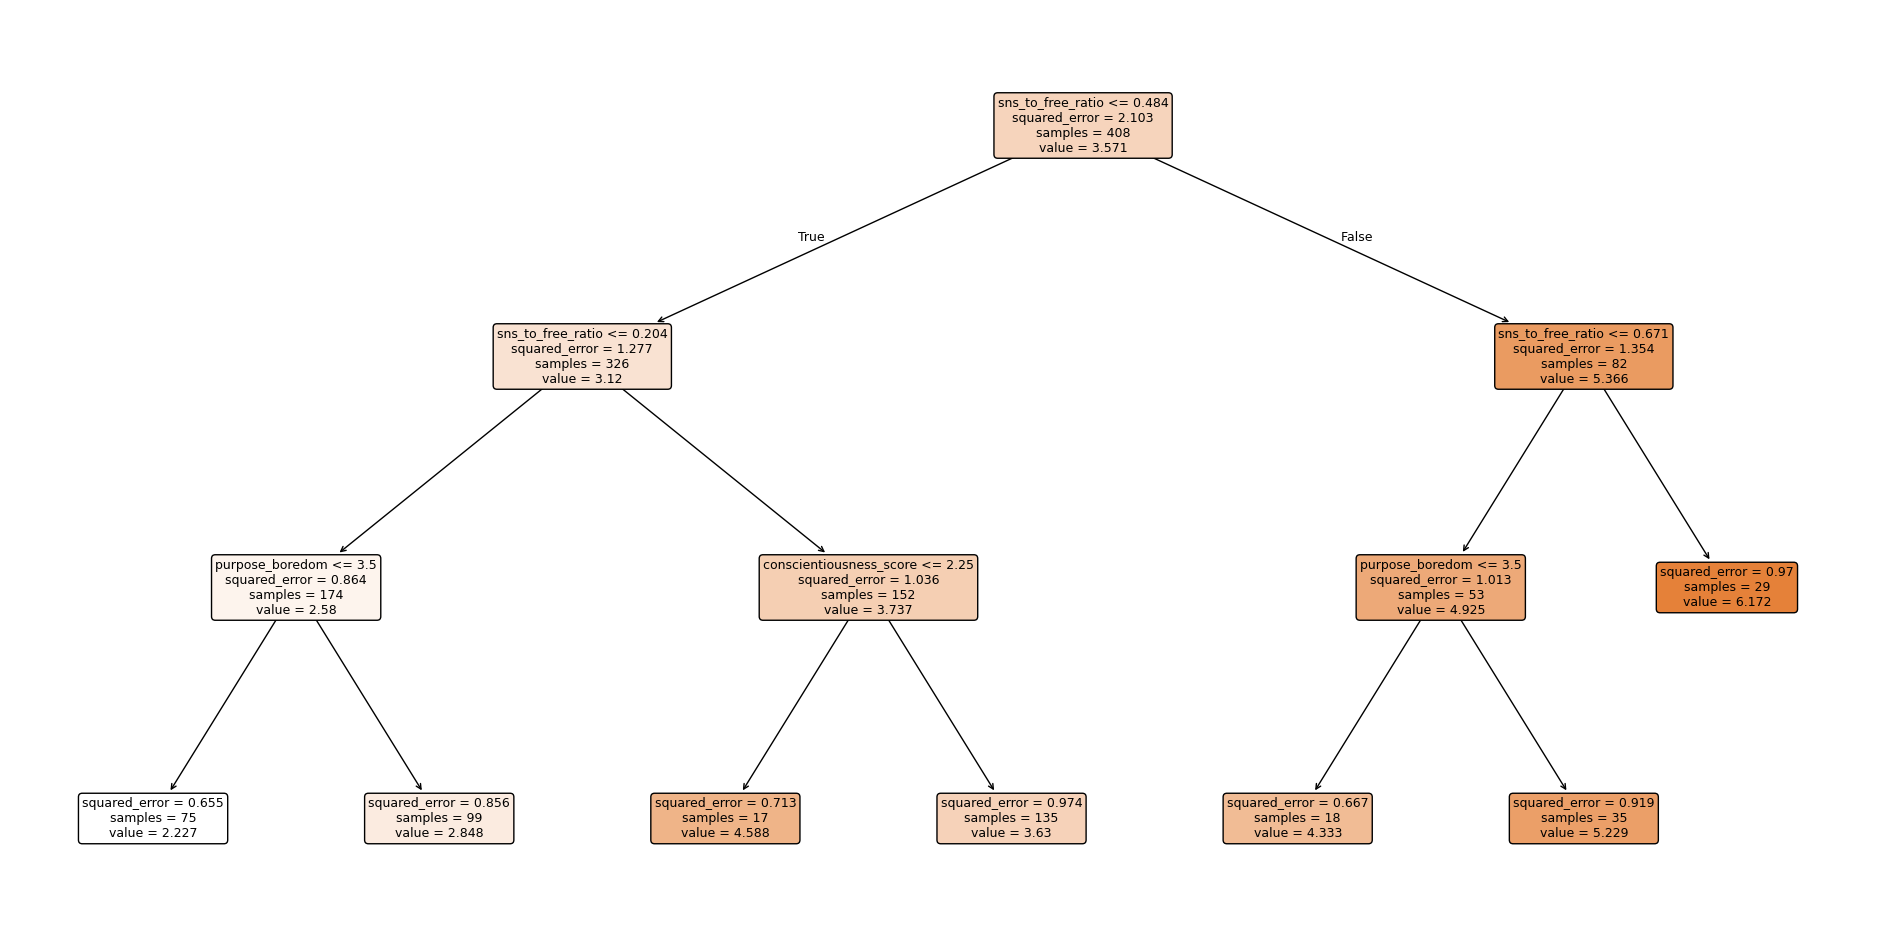

In [ ]:
# =========================
# 決定木分析：YouTube × regret
# =========================

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.model_selection import KFold, cross_val_score

# -------------------------
# 1. 説明変数
# -------------------------

features = [
    "daily_minutes",
    "sns_to_free_ratio",
    "total_sns_to_free_ratio",
    "sns_time_share",

    "purpose_boredom",
    "purpose_entertainment",
    "purpose_news",
    "purpose_hobby",
    "purpose_study_work",
    "purpose_communication",
    "purpose_posting",

    "extraversion_score",
    "agreeableness_score",
    "conscientiousness_score",
    "neuroticism_score",
    "openness_score"
]

X = youtube_df[features]

# 目的変数
y = youtube_df["regret_1_7"]

# -------------------------
# 2. 決定木モデル
# -------------------------

tree_model = DecisionTreeRegressor(
    max_depth=3,
    min_samples_leaf=15,
    random_state=42
)

# -------------------------
# 3. 5-fold Cross Validation
# -------------------------

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

tree_cv_mae = -cross_val_score(
    tree_model,
    X,
    y,
    cv=kf,
    scoring="neg_mean_absolute_error"
)

print("各FoldのMAE:")
print(tree_cv_mae)

print("\n平均MAE:")
print(tree_cv_mae.mean())

# -------------------------
# 4. 全データで学習
# -------------------------

tree_model.fit(X, y)

# -------------------------
# 5. Feature Importance
# -------------------------

importance_df = pd.DataFrame({
    "feature": features,
    "importance": tree_model.feature_importances_
}).sort_values(
    "importance",
    ascending=False
)

print("\nFeature Importance:")
print(importance_df)

# -------------------------
# 6. 決定木を可視化
# -------------------------

plt.figure(figsize=(24, 12))

plot_tree(
    tree_model,
    feature_names=features,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.show()

各FoldのMAE:
[0.78906504 0.70386179 0.73853659 0.81880658 0.75946502]

平均MAE:
0.7619470039144837

MAE標準偏差:
0.039740407594941254

Feature Importance:
                    feature  importance
1         sns_to_free_ratio    0.595983
4           purpose_boredom    0.064801
2   total_sns_to_free_ratio    0.045721
13  conscientiousness_score    0.036225
3            sns_time_share    0.035789
14        neuroticism_score    0.028387
0             daily_minutes    0.027359
15           openness_score    0.027181
12      agreeableness_score    0.025560
11       extraversion_score    0.022178
6              purpose_news    0.019901
8        purpose_study_work    0.018826
7             purpose_hobby    0.013957
10          purpose_posting    0.013441
5     purpose_entertainment    0.012812
9     purpose_communication    0.011881


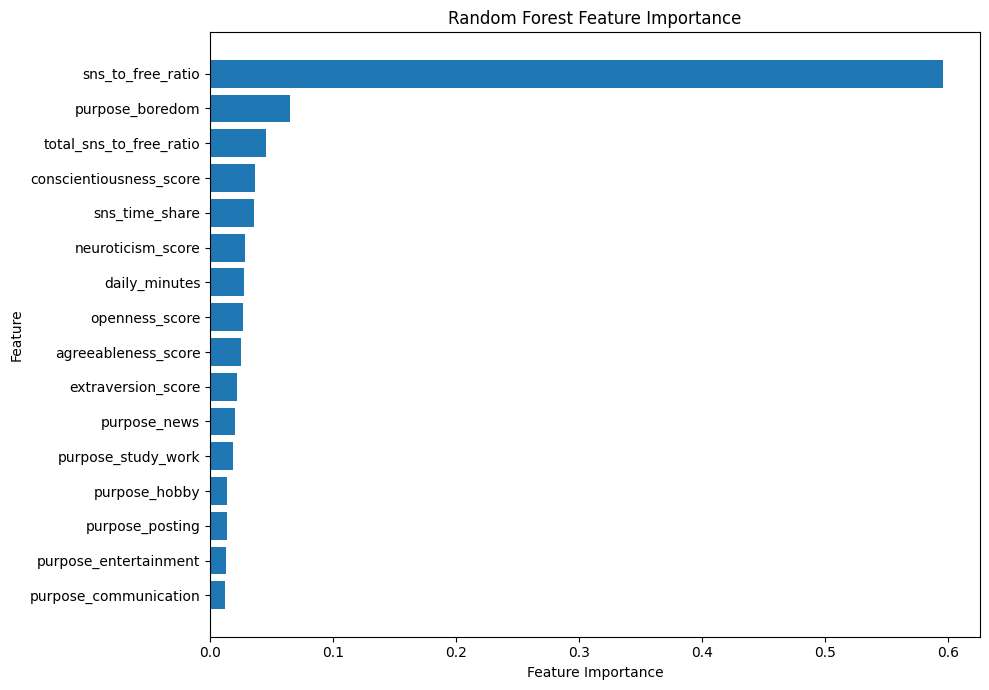

In [ ]:
# =========================
# Random Forest：YouTube × regret
# =========================

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_val_score

# -------------------------
# 1. 説明変数
# -------------------------

features = [
    "daily_minutes",
    "sns_to_free_ratio",
    "total_sns_to_free_ratio",
    "sns_time_share",

    "purpose_boredom",
    "purpose_entertainment",
    "purpose_news",
    "purpose_hobby",
    "purpose_study_work",
    "purpose_communication",
    "purpose_posting",

    "extraversion_score",
    "agreeableness_score",
    "conscientiousness_score",
    "neuroticism_score",
    "openness_score"
]

X = youtube_df[features]

# 目的変数
y = youtube_df["regret_1_7"]

# -------------------------
# 2. Random Forestモデル
# -------------------------

rf_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

# -------------------------
# 3. 5-fold Cross Validation
# -------------------------

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf_cv_mae = -cross_val_score(
    rf_model,
    X,
    y,
    cv=kf,
    scoring="neg_mean_absolute_error"
)

print("各FoldのMAE:")
print(rf_cv_mae)

print("\n平均MAE:")
print(rf_cv_mae.mean())

print("\nMAE標準偏差:")
print(rf_cv_mae.std())

# -------------------------
# 4. 全データで学習
# -------------------------

rf_model.fit(X, y)

# -------------------------
# 5. Feature Importance
# -------------------------

importance_df = pd.DataFrame({
    "feature": features,
    "importance": rf_model.feature_importances_
}).sort_values(
    "importance",
    ascending=False
)

print("\nFeature Importance:")
print(importance_df)

# -------------------------
# 6. Feature Importanceを可視化
# -------------------------

plt.figure(figsize=(10, 7))

plt.barh(
    importance_df["feature"][::-1],
    importance_df["importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")

plt.tight_layout()
plt.show()

In [ ]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 27.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 24.3 MB/s eta 0:00:00


In [ ]:
import optuna
import numpy as np

from lightgbm import LGBMRegressor
from sklearn.model_selection import KFold, cross_val_score

# =========================
# 1. 説明変数・目的変数
# =========================

features = [
    "daily_minutes",
    "sns_to_free_ratio",
    "total_sns_to_free_ratio",
    "sns_time_share",

    "purpose_boredom",
    "purpose_entertainment",
    "purpose_news",
    "purpose_hobby",
    "purpose_study_work",
    "purpose_communication",
    "purpose_posting",

    "extraversion_score",
    "agreeableness_score",
    "conscientiousness_score",
    "neuroticism_score",
    "openness_score"
]

X = youtube_df[features]
y = youtube_df["regret_1_7"]

# =========================
# 2. Cross Validation
# =========================

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# =========================
# 3. Optunaで最小化する関数
# =========================

def objective(trial):

    params = {
        "n_estimators": trial.suggest_int(
            "n_estimators",
            100,
            1000
        ),

        "learning_rate": trial.suggest_float(
            "learning_rate",
            0.01,
            0.2,
            log=True
        ),

        "num_leaves": trial.suggest_int(
            "num_leaves",
            5,
            50
        ),

        "max_depth": trial.suggest_int(
            "max_depth",
            2,
            10
        ),

        "min_child_samples": trial.suggest_int(
            "min_child_samples",
            5,
            50
        ),

        "subsample": trial.suggest_float(
            "subsample",
            0.6,
            1.0
        ),

        "colsample_bytree": trial.suggest_float(
            "colsample_bytree",
            0.6,
            1.0
        ),

        "reg_alpha": trial.suggest_float(
            "reg_alpha",
            0.0,
            5.0
        ),

        "reg_lambda": trial.suggest_float(
            "reg_lambda",
            0.0,
            5.0
        ),

        "random_state": 42,
        "verbosity": -1
    }

    model = LGBMRegressor(**params)

    cv_mae = -cross_val_score(
        model,
        X,
        y,
        cv=kf,
        scoring="neg_mean_absolute_error",
        n_jobs=-1
    )

    return cv_mae.mean()


# =========================
# 4. Optuna実行
# =========================

study = optuna.create_study(
    direction="minimize"
)

study.optimize(
    objective,
    n_trials=100
)

# =========================
# 5. 結果
# =========================

print("Best MAE:")
print(study.best_value)

print("\nBest Parameters:")
print(study.best_params)

[I 2026-09-13 08:45:23,747] A new study created in memory with name: no-name-79701ec9-608d-4808-a1b1-5a14104aa8ac
[I 2026-09-13 08:45:29,856] Trial 0 finished with value: 0.8276673163837472 and parameters: {'n_estimators': 522, 'learning_rate': 0.17575677918509378, 'num_leaves': 36, 'max_depth': 10, 'min_child_samples': 23, 'subsample': 0.7131749040661126, 'colsample_bytree': 0.9993293451078015, 'reg_alpha': 0.06979393160584435, 'reg_lambda': 3.7680315418918333}. Best is trial 0 with value: 0.8276673163837472.
[I 2026-09-13 08:45:30,026] Trial 1 finished with value: 0.7673321679823305 and parameters: {'n_estimators': 192, 'learning_rate': 0.08922311794541025, 'num_leaves': 15, 'max_depth': 7, 'min_child_samples': 37, 'subsample': 0.6511998069197656, 'colsample_bytree': 0.6585375399628559, 'reg_alpha': 2.0667937259274796, 'reg_lambda': 4.693283591630417}. Best is trial 1 with value: 0.7673321679823305.
[I 2026-09-13 08:45:30,528] Trial 2 finished with value: 0.7941377225007729 and param

Best MAE:
0.7328183348219184

Best Parameters:
{'n_estimators': 705, 'learning_rate': 0.06898055621607611, 'num_leaves': 5, 'max_depth': 2, 'min_child_samples': 8, 'subsample': 0.9022113370903898, 'colsample_bytree': 0.6530101984298013, 'reg_alpha': 4.691839120575145, 'reg_lambda': 4.350875398484954}
